# Top 20% decline prediction: model training (logistic regression, first pass)

**Premises**
- Final features: `KID_CATEGORY_DESC_encoded` excluded (VIF 26.7 is severe, and it duplicates the information of HOUSEHOLD_SIZE_DESC)
- Sample: 499 households (decline = 1: 223, stayed = 0: 276)
- Validation: StratifiedKFold 5-fold (keeps the label proportions)
- Metrics: PR-AUC, recall, ROC-AUC (accuracy is shown for reference only)

In [1]:
import pandas as pd
from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

pd.set_option('display.max_columns', 100)

RANDOM_STATE = SEED


## 1. Settle the final features and save

Save the final version, with `KID_CATEGORY_DESC_encoded` (severe in the VIF) removed, as a separate file.

In [2]:
encoded_table = pd.read_csv(INTERMEDIATE_DIR / "h4_shrink_feature_table_encoded.csv", index_col=0).sort_index()
encoded_table.index.name = "HOUSEHOLD_KEY"

feature_cols_final = [c for c in encoded_table.columns
                       if c not in ("label_shrink", "KID_CATEGORY_DESC_encoded")]

final_table = encoded_table[feature_cols_final + ["label_shrink"]].copy()
final_table.to_csv(INTERMEDIATE_DIR / "h4_shrink_feature_table_final.csv")

print(f"Final number of features: {len(feature_cols_final)}")
print(f"Final table shape: {final_table.shape}")
print(f"\nLabel distribution\n{final_table['label_shrink'].value_counts()}")
print(list(feature_cols_final))


Final number of features: 18
Final table shape: (499, 19)

Label distribution
label_shrink
0    276
1    223
Name: count, dtype: int64
['sales_early', 'n_baskets', 'avg_items_per_basket', 'category_diversity', 'exposure_ratio', 'has_demo', 'AGE_DESC_encoded', 'INCOME_DESC_encoded', 'HOUSEHOLD_SIZE_DESC_encoded', 'HOMEOWNER_DESC_Probable Owner', 'HOMEOWNER_DESC_Probable Renter', 'HOMEOWNER_DESC_Renter', 'HOMEOWNER_DESC_Unknown', 'HH_COMP_DESC_1 Adult Kids', 'HH_COMP_DESC_2 Adults Kids', 'HH_COMP_DESC_Single Female', 'HH_COMP_DESC_Single Male', 'HH_COMP_DESC_Unknown']


## 2. Split X and y, and choose what to scale

Standardize only the continuous-type features (5 numeric + 3 ordinal-encoded),
and do not scale the variables that are already 0/1 (has_demo, one-hot dummies).

In [3]:
X = final_table[feature_cols_final]
y = final_table["label_shrink"]

numeric_scale_cols = [
    "sales_early", "n_baskets", "avg_items_per_basket", "category_diversity", "exposure_ratio",
    "AGE_DESC_encoded", "INCOME_DESC_encoded", "HOUSEHOLD_SIZE_DESC_encoded",
]
binary_cols = [c for c in feature_cols_final if c not in numeric_scale_cols]

print(f"Standardized ({len(numeric_scale_cols)}): {numeric_scale_cols}")
print(f"\nUsed as is ({len(binary_cols)}): {binary_cols}")


Standardized (8): ['sales_early', 'n_baskets', 'avg_items_per_basket', 'category_diversity', 'exposure_ratio', 'AGE_DESC_encoded', 'INCOME_DESC_encoded', 'HOUSEHOLD_SIZE_DESC_encoded']

Used as is (10): ['has_demo', 'HOMEOWNER_DESC_Probable Owner', 'HOMEOWNER_DESC_Probable Renter', 'HOMEOWNER_DESC_Renter', 'HOMEOWNER_DESC_Unknown', 'HH_COMP_DESC_1 Adult Kids', 'HH_COMP_DESC_2 Adults Kids', 'HH_COMP_DESC_Single Female', 'HH_COMP_DESC_Single Male', 'HH_COMP_DESC_Unknown']


## 3. Build the preprocessing + model pipeline

Standardize only the scaling targets with a ColumnTransformer and connect it to logistic regression (L2 regularization).

In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), numeric_scale_cols),
        ("passthrough", "passthrough", binary_cols),
    ]
)

model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


## 4. Cross-validated performance (PR-AUC, recall, ROC-AUC)

In [5]:
scoring = {
    "pr_auc": "average_precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",  # for reference
}

cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=False)

results_summary = pd.DataFrame({
    "metric": list(scoring.keys()),
    "mean": [cv_results[f"test_{k}"].mean() for k in scoring],
    "std": [cv_results[f"test_{k}"].std() for k in scoring],
})
print("5-fold cross-validation results (mean ± standard deviation)")
print(results_summary)


5-fold cross-validation results (mean ± standard deviation)
     metric      mean       std
0    pr_auc  0.685158  0.048848
1    recall  0.600606  0.083851
2   roc_auc  0.737671  0.024970
3  accuracy  0.683394  0.022936


In [6]:
# --- source CSVs: per-fold and mean CV metrics (logistic regression)
pd.DataFrame({"fold": range(1, 6), **{k: cv_results[f"test_{k}"] for k in scoring}}) \
    .to_csv(OUT_DIR / "ml_logit_cv_folds.csv", index=False)
results_summary.to_csv(OUT_DIR / "ml_logit_cv_summary.csv", index=False)

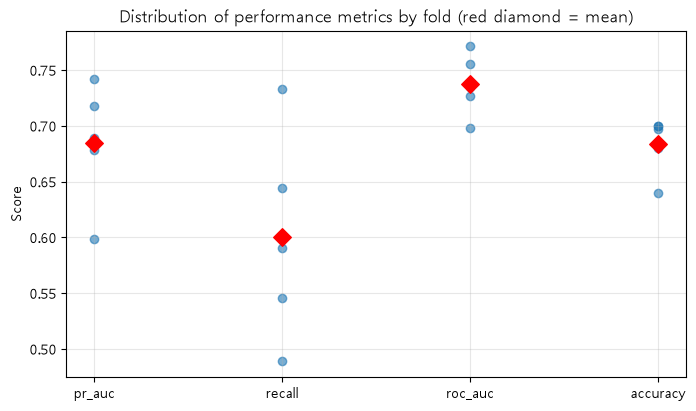

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, metric in enumerate(scoring.keys()):
    ax.scatter([i]*5, cv_results[f"test_{metric}"], alpha=0.6, color='C0')
    ax.scatter(i, cv_results[f"test_{metric}"].mean(), color='red', marker='D', s=80, zorder=5)
ax.set_xticks(range(len(scoring)))
ax.set_xticklabels(list(scoring.keys()))
ax.set_title("Distribution of performance metrics by fold (red diamond = mean)")
ax.set_ylabel("Score")
ax.grid(alpha=0.3)
plt.show()


## 5. Classification report + confusion matrix from out-of-fold predictions

Collect (without duplicates) the predictions that each fold's model made on its own validation set, and check the overall classification performance.

In [8]:
y_pred = cross_val_predict(model, X, y, cv=cv, method="predict")
y_proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]

print("Classification report (0 = stayed, 1 = declined)")
print(classification_report(y, y_pred, target_names=["stayed (0)", "declined (1)"]))

cm = confusion_matrix(y, y_pred)
print("Confusion matrix")
print(pd.DataFrame(cm, index=["actual stayed", "actual declined"], columns=["predicted stayed", "predicted declined"]))


Classification report (0 = stayed, 1 = declined)
              precision    recall  f1-score   support

  stayed (0)       0.70      0.75      0.72       276
declined (1)       0.66      0.60      0.63       223

    accuracy                           0.68       499
   macro avg       0.68      0.68      0.68       499
weighted avg       0.68      0.68      0.68       499

Confusion matrix
                 predicted stayed  predicted declined
actual stayed                 207                  69
actual declined                89                 134


In [9]:
# --- source CSVs: out-of-fold confusion matrix, classification report, OOF probabilities (intermediate)
_tn, _fp, _fn, _tp = cm.ravel()
pd.DataFrame([{
    "tn": _tn, "fp": _fp, "fn": _fn, "tp": _tp, "n": len(y),
    "n_actual_shrink": int(y.sum()), "n_actual_retain": int((y == 0).sum()),
    "fn_rate_pct": _fn / (_fn + _tp) * 100, "recall": _tp / (_tp + _fn), "precision": _tp / (_tp + _fp),
    "threshold": 0.5,
}]).to_csv(OUT_DIR / "ml_logit_confusion.csv", index=False)
pd.DataFrame(classification_report(y, y_pred, output_dict=True)).T.rename_axis("label").reset_index() \
    .to_csv(OUT_DIR / "ml_logit_classification_report.csv", index=False)
pd.DataFrame({"label_shrink": y, "y_pred": y_pred, "y_proba": y_proba}) \
    .to_csv(INTERMEDIATE_DIR / "ml_logit_oof.csv", index_label="household_key")

## 6. Final training on all the data: for interpreting the coefficients

**Note**: sections 4-5 above are for performance "evaluation" (each prediction comes from a fold that was not used for training),
while the model below is a separate one retrained on all the data for coefficient "interpretation". Do not look at performance metrics here again (they would be overfitted values).

In [10]:
model.fit(X, y)

coef = model.named_steps["clf"].coef_[0]
feature_names = numeric_scale_cols + binary_cols  # same as the ColumnTransformer output order

coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coef,
    "odds_ratio": np.exp(coef),
}).sort_values("odds_ratio", ascending=False, kind="stable")

print("Coefficients and odds ratios (odds_ratio > 1 raises the chance of decline, < 1 lowers it)")
print(coef_table)


Coefficients and odds ratios (odds_ratio > 1 raises the chance of decline, < 1 lowers it)
                           feature  coefficient  odds_ratio
9    HOMEOWNER_DESC_Probable Owner     0.422954    1.526464
12          HOMEOWNER_DESC_Unknown     0.371489    1.449892
1                        n_baskets     0.255164    1.290674
7      HOUSEHOLD_SIZE_DESC_encoded     0.137039    1.146873
2             avg_items_per_basket     0.046075    1.047153
11           HOMEOWNER_DESC_Renter    -0.026243    0.974098
4                   exposure_ratio    -0.036752    0.963915
5                 AGE_DESC_encoded    -0.072125    0.930415
3               category_diversity    -0.303821    0.737993
6              INCOME_DESC_encoded    -0.312111    0.731900
16        HH_COMP_DESC_Single Male    -0.330557    0.718524
0                      sales_early    -0.443316    0.641904
15      HH_COMP_DESC_Single Female    -0.597559    0.550153
10  HOMEOWNER_DESC_Probable Renter    -0.606003    0.545527
17        

In [11]:
# --- source CSV: odds ratios. L2 model = the one used for prediction; MLE columns give Wald CI and p
import warnings
import statsmodels.api as sm
from sklearn.base import clone

_Xs = pd.DataFrame(model.named_steps["preprocess"].transform(X), columns=feature_names, index=X.index)
_mle_status = "ok"
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _mle = sm.Logit(y, sm.add_constant(_Xs)).fit(disp=0, maxiter=200)
    _ci = _mle.conf_int()
    _coef_mle = _mle.params[feature_names].values
    _ci_lo, _ci_hi = _ci.loc[feature_names, 0].values, _ci.loc[feature_names, 1].values
    _p_mle = _mle.pvalues[feature_names].values
except Exception as e:  # e.g. perfect separation on a rare dummy
    _mle_status = f"failed: {type(e).__name__}"
    _coef_mle = _ci_lo = _ci_hi = _p_mle = np.full(len(feature_names), np.nan)

N_BOOT_OR = 1000
_rng_or = np.random.default_rng(SEED)
_Xb, _yb = X.reset_index(drop=True), y.reset_index(drop=True)
_boot = np.empty((N_BOOT_OR, len(feature_names)))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for _b in range(N_BOOT_OR):
        _idx = _rng_or.integers(0, len(_Xb), len(_Xb))
        _boot[_b] = clone(model).fit(_Xb.iloc[_idx], _yb.iloc[_idx]).named_steps["clf"].coef_[0]

with np.errstate(over="ignore"):  # exp of an unbounded Wald bound -> inf is expected
    odds_table = pd.DataFrame({
        "feature": feature_names,
        "scaled_per_1sd": [f in numeric_scale_cols for f in feature_names],
        "feature_sd": [dict(zip(numeric_scale_cols, model.named_steps["preprocess"].named_transformers_["scale"].scale_)).get(f, np.nan)
                       for f in feature_names],
        "coef_l2": coef, "odds_ratio_l2": np.exp(coef),
        "or_l2_boot_ci_low": np.exp(np.percentile(_boot, 2.5, axis=0)),
        "or_l2_boot_ci_high": np.exp(np.percentile(_boot, 97.5, axis=0)),
        "coef_mle": _coef_mle, "odds_ratio_mle": np.exp(_coef_mle),
        "or_mle_ci_low": np.exp(_ci_lo), "or_mle_ci_high": np.exp(_ci_hi), "p_value_mle": _p_mle,
        "mle_unstable": np.abs(_coef_mle) > 20, "mle_status": _mle_status, "n_boot": N_BOOT_OR, "seed": SEED,
    })
    odds_table.sort_values("odds_ratio_l2", ascending=False, kind="stable").to_csv(OUT_DIR / "ml_logit_odds_ratios.csv", index=False)

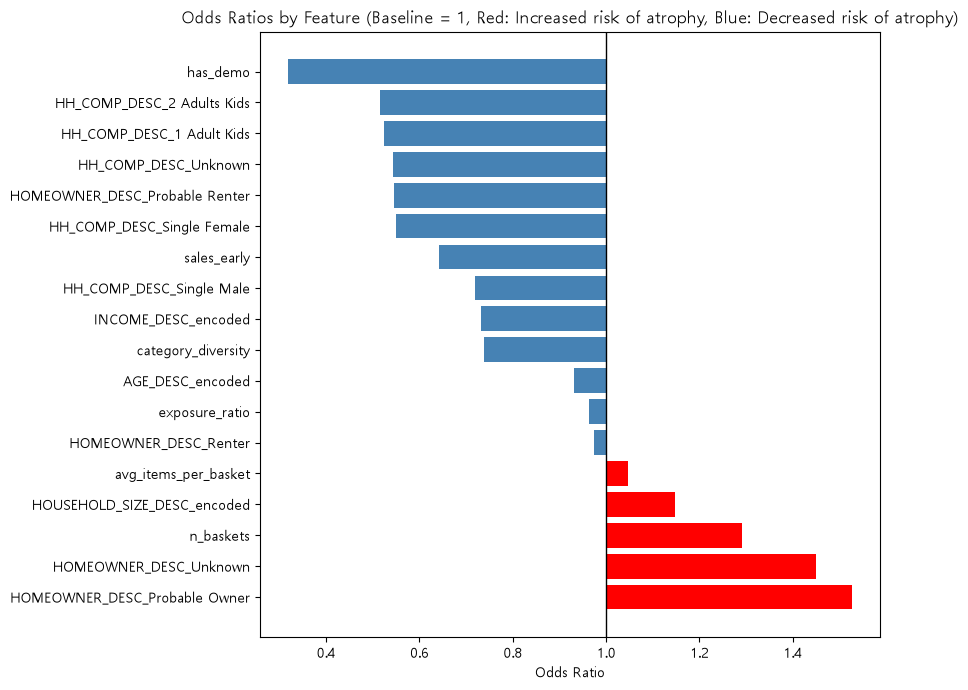

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
colors = ['red' if v > 1 else 'steelblue' for v in coef_table["odds_ratio"]]
ax.barh(coef_table["feature"], coef_table["odds_ratio"] - 1, left=1, color=colors)
ax.axvline(1, color='black', linewidth=1)
ax.set_xlabel("Odds Ratio")
ax.set_title("Odds Ratios by Feature (Baseline = 1, Red: Increased risk of atrophy, Blue: Decreased risk of atrophy)")
plt.tight_layout()
plt.show()


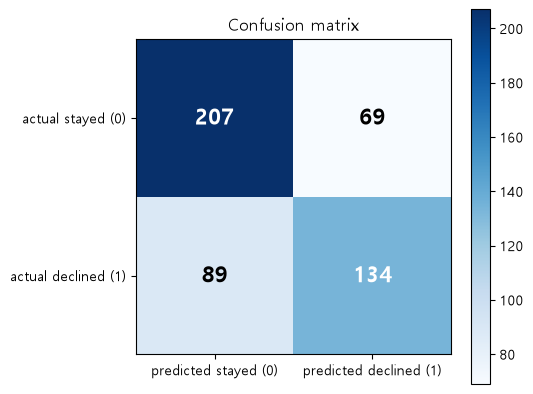

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")

labels_display = ["stayed (0)", "declined (1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels([f"predicted {l}" for l in labels_display])
ax.set_yticklabels([f"actual {l}" for l in labels_display])

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black",
                 fontsize=16, fontweight="bold")

ax.set_title("Confusion matrix")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## 7. Interpretation guide

- **Features with an odds ratio > 1**: the larger the value (or the more the household belongs to that category), the higher the chance of decline
- **Features with an odds ratio < 1**: the larger the value, the lower the chance of decline (favorable for staying)
- Compare whether the coefficient directions match the signals seen in the earlier basic statistics by group (sales_early and category_diversity higher in the stayed group, exposure_ratio the opposite);
  if they match, the statistical exploration and the model results cross-validate each other
- Next step: check nonlinear relationships and interactions with random forest + SHAP and compare with the logistic results

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import permutation_test_score, learning_curve

# ---- 1) Permutation test: could this performance arise by chance? ----
score, perm_scores, pvalue = permutation_test_score(
    model, X, y, cv=cv, scoring="average_precision",
    n_permutations=1000, random_state=RANDOM_STATE, n_jobs=-1
)

print(f"Actual PR-AUC: {score:.4f}")
print(f"PR-AUC distribution with shuffled labels: mean={perm_scores.mean():.4f}, SD={perm_scores.std():.4f}")
print(f"p-value: {pvalue:.4f}")
print(f"-> {'Meaningful learning, not chance' if pvalue < 0.05 else 'Statistically indistinguishable from chance; take care'}")

Actual PR-AUC: 0.6852
PR-AUC distribution with shuffled labels: mean=0.4702, SD=0.0279
p-value: 0.0010
-> Meaningful learning, not chance


In [15]:
# --- source CSV: permutation test
pd.DataFrame([{
    "pr_auc_actual": score, "pr_auc_perm_mean": perm_scores.mean(), "pr_auc_perm_std": perm_scores.std(),
    "p_value": pvalue, "n_permutations": 1000, "seed": SEED,
}]).to_csv(OUT_DIR / "ml_permutation_test.csv", index=False)

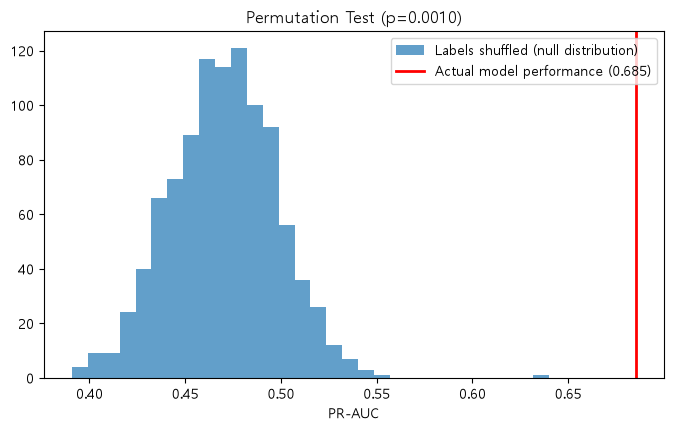

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(perm_scores, bins=30, alpha=0.7, label="Labels shuffled (null distribution)")
ax.axvline(score, color='red', linewidth=2, label=f"Actual model performance ({score:.3f})")
ax.set_xlabel("PR-AUC")
ax.set_title(f"Permutation Test (p={pvalue:.4f})")
ax.legend()
plt.show()

In [17]:
# ---- 2) Comparison with the Dummy classifier ----
dummy_stratified = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
dummy_scores = cross_validate(dummy_stratified, X, y, cv=cv, scoring=scoring)

print("Dummy (strategy = stratified, random predictions following only the label proportions) baseline")
for k in scoring:
    print(f"  {k}: {dummy_scores[f'test_{k}'].mean():.4f}")

print(f"\nImprovement of the actual logistic model over the baseline (PR-AUC): "
      f"{score - dummy_scores['test_pr_auc'].mean():+.4f}")

Dummy (strategy = stratified, random predictions following only the label proportions) baseline
  pr_auc: 0.4325
  recall: 0.3673
  roc_auc: 0.4608
  accuracy: 0.4708

Improvement of the actual logistic model over the baseline (PR-AUC): +0.2526


In [18]:
# --- source CSV: baselines (prevalence and stratified dummy classifier)
pd.DataFrame([{
    "n": len(y), "n_positive": int(y.sum()), "prevalence": y.mean(),
    **{f"dummy_{k}": dummy_scores[f"test_{k}"].mean() for k in scoring},
    "logit_pr_auc": score, "pr_auc_gain_over_dummy": score - dummy_scores["test_pr_auc"].mean(),
}]).to_csv(OUT_DIR / "ml_baselines.csv", index=False)

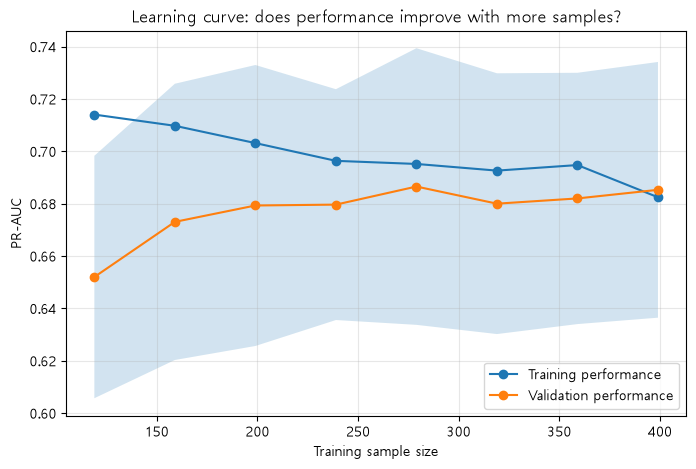

Final gap between training and validation performance: -0.0028
-> A large gap means overfitting (fits training well but is weak on new data); a small gap means no overfitting


In [19]:
# ---- 3) Learning curve: does it improve with more samples? ----
train_sizes, train_scores, val_scores = learning_curve(
    model, X, y, cv=cv, scoring="average_precision",
    train_sizes=np.linspace(0.3, 1.0, 8), shuffle=True, random_state=RANDOM_STATE, n_jobs=-1
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_sizes, train_scores.mean(axis=1), marker='o', label="Training performance")
ax.plot(train_sizes, val_scores.mean(axis=1), marker='o', label="Validation performance")
ax.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
ax.set_xlabel("Training sample size")
ax.set_ylabel("PR-AUC")
ax.set_title("Learning curve: does performance improve with more samples?")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print(f"Final gap between training and validation performance: {train_scores.mean(axis=1)[-1] - val_scores.mean(axis=1)[-1]:.4f}")
print("-> A large gap means overfitting (fits training well but is weak on new data); a small gap means no overfitting")

In [20]:
# --- source CSV: learning curve
pd.DataFrame({
    "train_size": train_sizes,
    "train_pr_auc_mean": train_scores.mean(axis=1), "train_pr_auc_std": train_scores.std(axis=1),
    "val_pr_auc_mean": val_scores.mean(axis=1), "val_pr_auc_std": val_scores.std(axis=1),
}).to_csv(OUT_DIR / "ml_learning_curve.csv", index=False)

## Observe how recall and precision change when the logistic-regression threshold is adjusted

In [21]:
from sklearn.metrics import precision_recall_curve, f1_score

precisions, recalls, thresholds = precision_recall_curve(y, y_proba)

# precision_recall_curve returns one fewer threshold than precisions/recalls (correct for the last point)
precisions = precisions[:-1]
recalls = recalls[:-1]

pr_table = pd.DataFrame({
    "threshold": thresholds,
    "precision": precisions,
    "recall": recalls,
})
pr_table["f1"] = 2 * pr_table["precision"] * pr_table["recall"] / (pr_table["precision"] + pr_table["recall"])

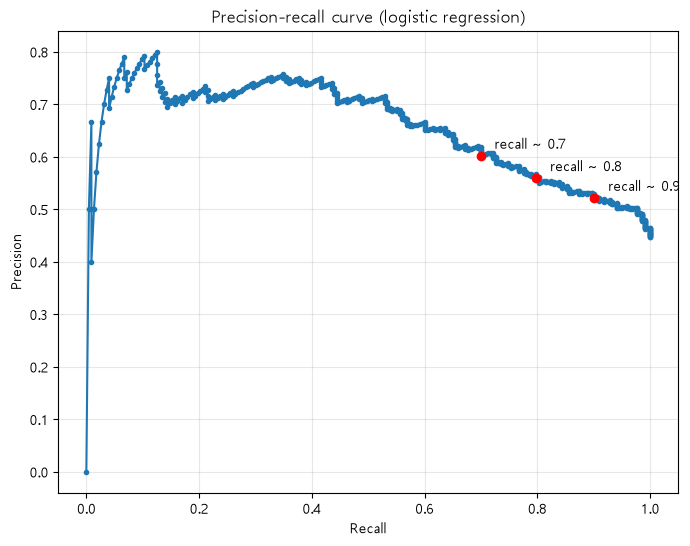

In [22]:
# Plot the whole curve: see at a glance how much precision must be sacrificed to raise recall
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recalls, precisions, marker='.')
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curve (logistic regression)")
ax.grid(alpha=0.3)

for target_recall in [0.7, 0.8, 0.9]:
    idx = (pr_table["recall"] - target_recall).abs().idxmin()
    ax.annotate(f"recall ~ {target_recall}", (recalls[idx], precisions[idx]),
                textcoords="offset points", xytext=(10, 5))
    ax.scatter(recalls[idx], precisions[idx], color='red', zorder=5)

plt.show()

In [23]:
# Table by threshold: look closely in steps of 0.05
threshold_grid = np.arange(0.1, 0.9, 0.05)
rows = []
for t in threshold_grid:
    y_pred_t = (y_proba >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precisions[np.argmin(np.abs(thresholds - t))] if len(thresholds) > 0 else np.nan,
        "recall": ((y_pred_t == 1) & (y == 1)).sum() / (y == 1).sum(),
        "precision_actual": ((y_pred_t == 1) & (y == 1)).sum() / max((y_pred_t == 1).sum(), 1),
        "f1": f1_score(y, y_pred_t),
        "n_predicted_at_risk": (y_pred_t == 1).sum(),
    })

threshold_table = pd.DataFrame(rows)
threshold_table

,threshold,precision,recall,precision_actual,f1,n_predicted_at_risk
0,0.10,0.469214,0.991031,0.469214,0.636888,471
1,0.15,0.488889,0.986547,0.489978,0.654762,449
2,0.20,0.503529,0.959641,0.503529,0.660494,425
3,0.25,0.526178,0.901345,0.526178,0.664463,382
4,0.30,0.541787,0.843049,0.543353,0.660808,346
5,0.35,0.566879,0.798206,0.566879,0.662942,314
6,0.40,0.590580,0.726457,0.589091,0.650602,275
7,0.45,0.619835,0.672646,0.619835,0.645161,242
8,0.50,0.656863,0.600897,0.660099,0.629108,203
9,0.55,0.687500,0.542601,0.691429,0.608040,175


In [24]:
# Goal: find the highest threshold (the one sacrificing the least precision) that satisfies recall >= 0.8
candidates = threshold_table[threshold_table["recall"] >= 0.8]
if len(candidates) > 0:
    best_row = candidates.sort_values("threshold", ascending=False, kind="stable").iloc[0]
    print("The highest threshold (minimum precision loss) among those satisfying recall >= 0.8")
    print(best_row)
else:
    print("No threshold in the grid satisfies recall >= 0.8; search again with lower thresholds")

The highest threshold (minimum precision loss) among those satisfying recall >= 0.8
threshold                0.300000
precision                0.541787
recall                   0.843049
precision_actual         0.543353
f1                       0.660808
n_predicted_at_risk    346.000000
Name: 4, dtype: float64


In [25]:
# Compare the default (0.5) with the adjusted threshold
default_recall = threshold_table.loc[threshold_table["threshold"] == 0.50, "recall"].values[0]
print(f"Recall at the default threshold (0.5): {default_recall:.3f}")
print(f"Recall at the adjusted threshold ({best_row['threshold']:.2f}): {best_row['recall']:.3f}")
print(f"Precision at that point: {best_row['precision_actual']:.3f}")
print(f"Households classified as at risk: {best_row['n_predicted_at_risk']:.0f} (of 499 in total)")

Recall at the default threshold (0.5): 0.601
Recall at the adjusted threshold (0.30): 0.843
Precision at that point: 0.543
Households classified as at risk: 346 (of 499 in total)


In [26]:
# --- source CSVs: precision-recall curve and threshold table
pr_table.to_csv(OUT_DIR / "ml_pr_curve.csv", index=False)
threshold_table.to_csv(OUT_DIR / "ml_threshold_table.csv", index=False)
pd.DataFrame([best_row]).to_csv(OUT_DIR / "ml_threshold_choice.csv", index=False)

In [27]:
def risk_tier(prob):
    if prob >= 0.6:
        return "high risk (act immediately)"
    elif prob >= 0.35:
        return "medium risk (monitor + low-cost campaign)"
    else:
        return "low risk"

risk_segments = pd.Series([risk_tier(p) for p in y_proba], index=y.index)
segment_summary = pd.DataFrame({"risk_tier": risk_segments, "actual_label": y})

print(segment_summary["risk_tier"].value_counts())
print("\nActual decline rate by segment (check whether the model separated them well)")
print(segment_summary.groupby("risk_tier")["actual_label"].mean())

risk_tier
low risk                                     185
medium risk (monitor + low-cost campaign)    158
high risk (act immediately)                  156
Name: count, dtype: int64

Actual decline rate by segment (check whether the model separated them well)
risk_tier
high risk (act immediately)                  0.705128
low risk                                     0.243243
medium risk (monitor + low-cost campaign)    0.430380
Name: actual_label, dtype: float64


In [28]:
# --- source CSV: risk tiers
segment_summary.assign(risk_tier=segment_summary["risk_tier"].map({
    "high risk (act immediately)": "high", "medium risk (monitor + low-cost campaign)": "medium", "low risk": "low"})) \
    .groupby("risk_tier").agg(n=("actual_label", "size"), shrink_rate=("actual_label", "mean")) \
    .reset_index().to_csv(OUT_DIR / "ml_risk_tiers.csv", index=False)